# Gaze, gratitude and revisable scene models

**Goal.** Reproduce the paper's Figure 5 before bars, distinguish unavailable
after code from authored transfer, and test active inquiry using admitted
Realizing Emptiness structural priors. This is a simulation of sampled
locations, not recorded eye tracking or a pixel-based vision model.

Run from the repository in the frozen project environment. Every code cell
is executed by the canonical pipeline. The [source dossier](../docs/yarbus-research.md)
records discrepancies, primary scholarship and the original artwork license.

In [1]:
import sys
from thanks_for_nothing.notebooks import notebook_context
context = notebook_context()
from dataclasses import asdict
from importlib.metadata import version
from pathlib import Path
from tempfile import TemporaryDirectory
from pprint import pprint
import numpy as np
from IPython.display import Image, Markdown, display
from thanks_for_nothing.artifacts import write_record
from thanks_for_nothing.experiments import run_learning_experiment
print({name: version(name) for name in (
    'thanks-for-nothing', 'generalized-notation-notation', 'realizing-emptiness')})
print('Interpreter:', sys.executable)
root = context.root
if root is None:
    raise RuntimeError('Run this companion from the repository root or notebooks directory')

{'thanks-for-nothing': '0.11.0', 'generalized-notation-notation': '4.1.0', 'realizing-emptiness': '3.0.0'}
Interpreter: /Volumes/GitVault/Local/environments/tfn-release-20261022-311/bin/python


In [2]:
from thanks_for_nothing.gaze_design import load_gaze_task
from thanks_for_nothing.source_yarbus import run_yarbus_cohort
task = load_gaze_task(context.specifications)
source = run_yarbus_cohort(task.design, root=root)
print('Positive/negative/neutral occupancy (%)')
print('Source positive profile:', source.positive_percent)
print('Source negative profile:', source.negative_percent)
assert source.published_before_matches
assert not source.after_intervention_available
assert np.allclose(source.positive_percent, (82.14, 10.98, 6.88))
assert np.allclose(source.negative_percent, (54.62, 11.80, 33.58))

Positive/negative/neutral occupancy (%)
Source positive profile: (82.14, 10.979999999999999, 6.88)
Source negative profile: (54.620000000000005, 11.799999999999999, 33.58)


## 1. Reproduction scope and the missing intervention

Original seed 42 is set once, alternating positive and negative templates
across five pairs of 1,000 states. The initial neutral state is counted.
Cached notebook bars disagree with this code and are not the oracle.
The paper's after bars are visually available but have no corresponding
learning or before/after loop in the preserved gaze notebook. We do not
tune parameters to those values. Original policies penalize conditional
entropy; that term alone is not expected information gain.

In [3]:
from thanks_for_nothing.gaze import build_gaze_audit
learning = run_learning_experiment(specification_dir=context.specifications)
gaze = build_gaze_audit(learning, root=root, specification_dir=context.specifications)
assert gaze.all_controls_pass
print('Transfer records:', len(gaze.transfer), 'active episodes:', len(gaze.episodes),
      'exploratory contrasts:', len(gaze.contrasts))
pprint(gaze.controls)

Transfer records: 40960 active episodes: 18432 exploratory contrasts: 58
{'active_potential_outcomes_paired': True,
 'episode_outputs_valid': True,
 'native_evidence_oracle': True,
 'restricted_support_preserved': True,
 'sham_exact': True,
 'source_before_rounded_reproduction': True,
 'transfer_baselines_paired': True,
 'transfer_probability_closure': True,
 'transfer_valuation_null': True}


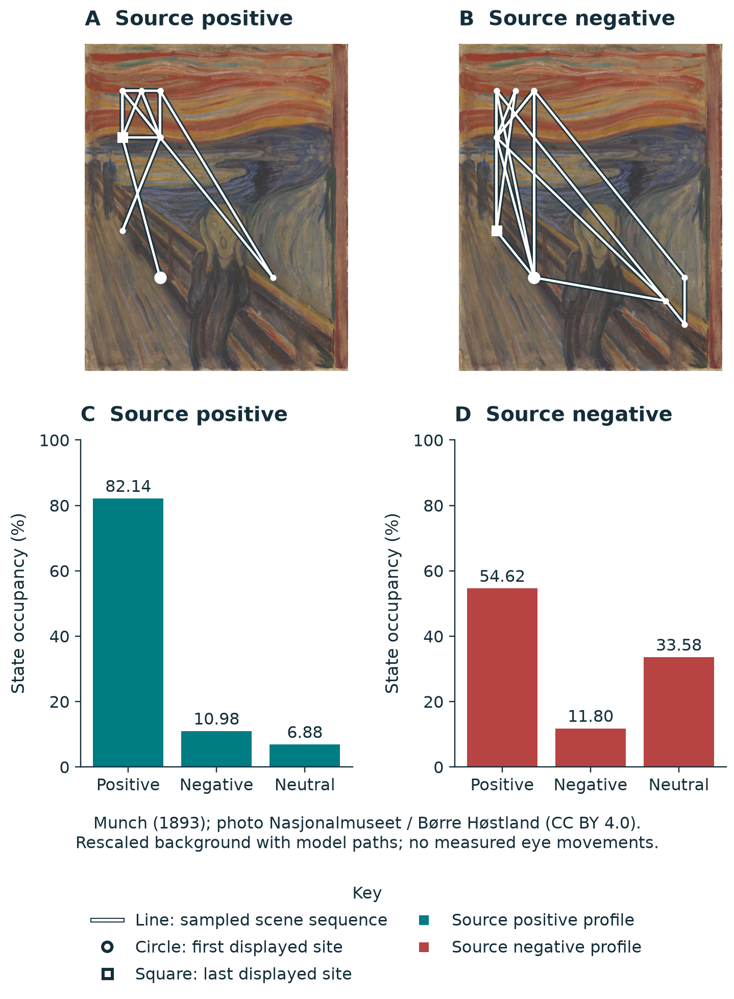

Paths show 20 locations; occupancy pools 5000 states/profile.


In [4]:
from thanks_for_nothing.gaze_art import copy_artwork
from thanks_for_nothing.gaze_figures import (
    yarbus_reconstruction, gaze_transfer_paths, gaze_inquiry_paths)
workspace = TemporaryDirectory(prefix='tfn-gaze-companion-')
destination = Path(workspace.name)
write_record(destination / 'data/gaze.json', gaze)
write_record(destination / 'data/study.json', learning.study)
copy_artwork(root, destination)
figure = yarbus_reconstruction(gaze, destination / 'figures')
display(Image(filename=str(destination / 'figures/yarbus_reconstruction.png'),
              alt=figure.alt))
print(figure.alt)

## 2. Transfer the trained channel, not the assessment data

Primary bridge: `A_scene = A_learned @ E`, using the admitted embedding
shown below. Each column specifies the declared latent-state weights for
a sampled scene location. Assessment-readout projection is retained
separately. Both use identical preferences, scene process and paired random
inputs. A path is one example; policy expectations and paired risk summarize
the complete study. Circle marks the first location and square the last;
straight segments join sampled states without cubic interpolation.

In [5]:
from thanks_for_nothing.notebooks import gaze_design_markdown
display(Markdown(gaze_design_markdown(context.specifications)))

**Admitted scene:** 2-by-13 transfer embedding; risk over all 13 locations; uniform-location regional baseline (5/13, 5/13, 3/13).

**Declared policies:** 6 policies: `pragmatic_restricted`, `pragmatic_open`, `inquiry_open`, `inquiry_restricted`, `sham`, `uniform_open`.

**Structural support:** restricted prior excludes [2]; open prior admits [0, 1, 2].

Direct likelihood transfer gave a positive-recall-minus-no-recall change in positive-location probability of +0.038492 [+0.038312, +0.038670]; multiplying by 100 gives 3.849 percentage points. The corresponding scene-risk change was +0.002362 [+0.002175, +0.002557] nats per outcome, indicating worse prediction under this bridge. The readout bridge instead gave -0.004677 [-0.004693, -0.004661] probability units. All brackets are pointwise bootstrap t intervals, not multiplicity-adjusted tests. Open inquiry minus restricted utility changed scene-wide prequential log loss by +0.009639 [+0.008892, +0.010535] in the stationary context and -0.115884 [-0.116824, -0.114765] in the reversal context. Access to the omitted candidate explains the reversal advantage: open utility and uniform open sampling also improve over the restricted reference. The full table retains the direct inquiry-versus-open-utility and inquiry-versus-uniform comparisons; their risk intervals include zero.

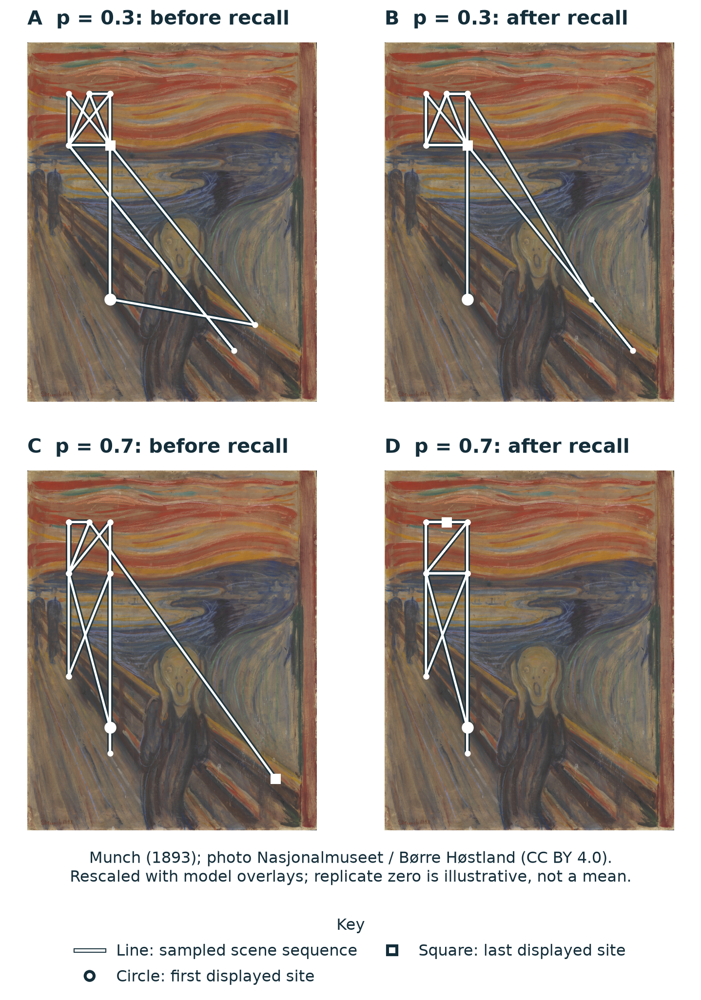

Paired pre/post recall paths at actual luckiness strata, using the new declared transfer rule.


In [6]:
from thanks_for_nothing.gaze_findings import gaze_main_findings
display(Markdown(gaze_main_findings(gaze)))
figure = gaze_transfer_paths(gaze, destination / 'figures')
display(Image(filename=str(destination / 'figures/gaze_transfer_paths.png'),
              alt=figure.alt))
print(figure.alt)

## 3. Check expected information gain independently

For each location enumerate outcomes: `H[p(o)] - E_q H[p(o|h)]` equals
expected posterior KL. This quantity vanishes for identical channels or
a known candidate. The active policy weights expected observation value
plus this information gain minus declared movement cost; it is a one-step
authored policy, not a full expected-free-energy planner.

In [7]:
from thanks_for_nothing.gaze_math import region_prediction
channels = np.asarray(task.design.channels)
q = np.asarray(task.model.tensors.D)
prediction, information = region_prediction(channels, q)
oracle = []
for channel, marginal in zip(channels, prediction, strict=True):
    expected_kl = 0.0
    for outcome, probability in enumerate(marginal):
        posterior = channel[outcome] * q / probability
        expected_kl += probability * np.sum(posterior * np.log(posterior / q))
    oracle.append(expected_kl)
assert np.allclose(information, oracle, atol=1e-12)
_, known_gain = region_prediction(channels, np.array([1.0, 0.0, 0.0]))
identical = np.repeat(channels[:, :, :1], 3, axis=2)
_, null_gain = region_prediction(identical, q)
assert np.allclose(known_gain, 0, atol=1e-12)
assert np.allclose(null_gain, 0, atol=1e-12)
print('Information gain by region (nats):', information)

Information gain by region (nats): [0.10689361 0.10689361 0.15945543]


## 4. Transpose inquiry into the Realizing Emptiness setting

The admitted support and policy inventory are displayed above from the
selected declarations. Policies separate structural access from information-seeking
action. Stationary and reversal contexts share potential
outcome uniforms across policies. Priors reset for each episode; candidate
identity is stable within an episode. This is not cross-window learning.

Risk is the exact cross-entropy over **every declared location**, scored before each
update. Preferentially visited locations cannot make their own test set look
better. There is no pixel inference: context changes regional channels while
the licensed painting stays fixed as a display background.

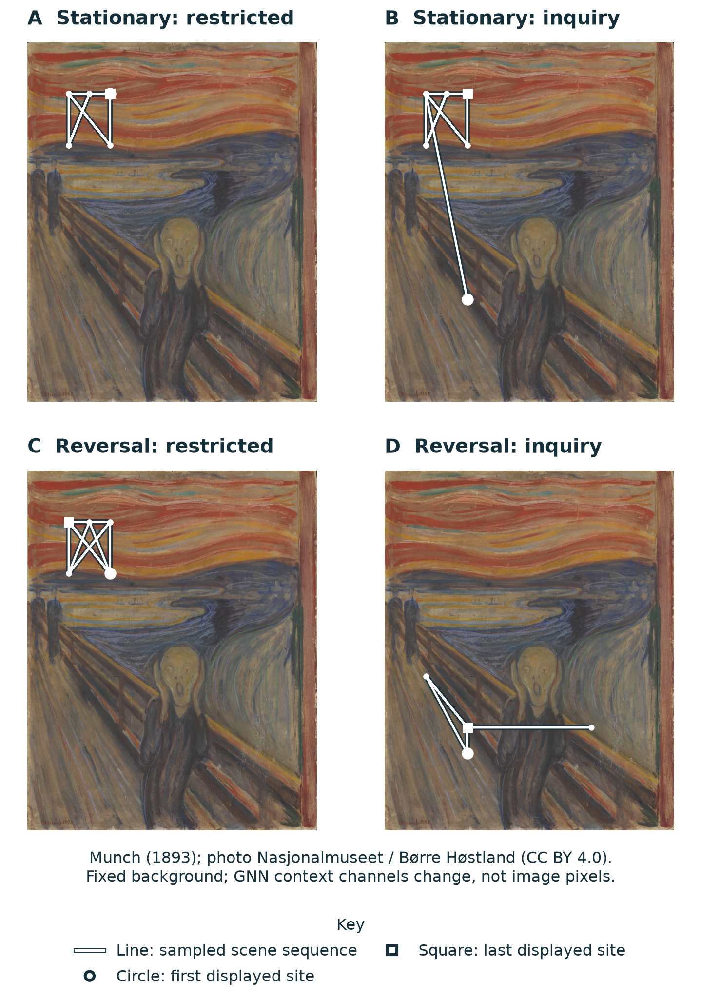

Sampled paths in stable and reversed channels; conditions share potential outcomes.


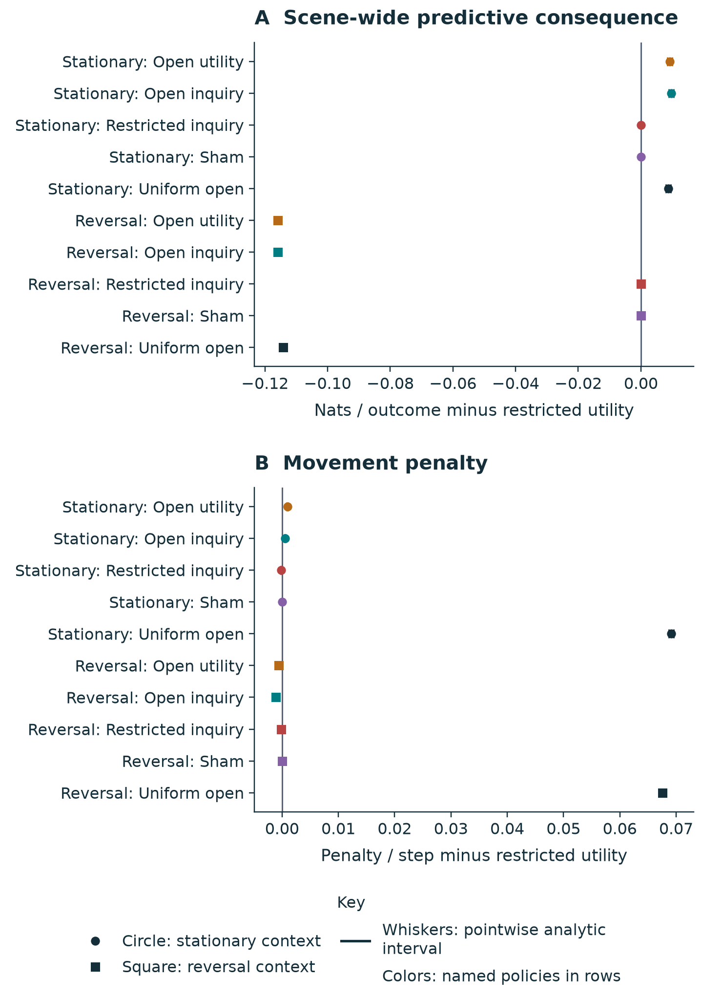

Paired intervals retain stationary/reversal contexts and movement costs.


In [8]:
figure = gaze_inquiry_paths(gaze, destination / 'figures')
display(Image(filename=str(destination / 'figures/gaze_inquiry_paths.png'),
              alt=figure.alt))
print(figure.alt)
from thanks_for_nothing.gaze_summary_figures import gaze_inquiry_summary
figure = gaze_inquiry_summary(gaze, destination / 'figures')
display(Image(filename=str(destination / 'figures/gaze_inquiry_summary.png'),
              alt=figure.alt))
print(figure.alt)

## 5. Describe paths without treating fixations as independent subjects

Coverage, revisit fraction, distance and joint transition entropy describe
discrete sequences. Revisit fraction counts samples beyond the first visit
to each location. Region occupancy is divided by the uniform-location
baseline displayed above from the admitted regional assignment. Geometry is a declared
unit square, not degrees of visual angle. These are descriptive metrics,
without a human dwell-time or saccade-speed interpretation.

In [9]:
from thanks_for_nothing.gaze_metrics import path_metrics
for row in gaze.episodes:
    if row.replicate == 0 and row.window == gaze.design.example_window:
        print(row.context, row.condition)
        pprint(asdict(path_metrics(row.locations, gaze.design)))

stationary pragmatic_restricted
{'mean_step_length': 0.10530856878374929,
 'occupancy_over_uniform_locations': (2.5999999999999996, 0.0, 0.0),
 'region_occupancy': (1.0, 0.0, 0.0),
 'revisit_fraction': 0.8958333333333334,
 'samples': 48,
 'transition_entropy_bits': 4.061380139605636,
 'unique_locations': 5}
stationary pragmatic_open
{'mean_step_length': 0.10656757657211735,
 'occupancy_over_uniform_locations': (2.5999999999999996, 0.0, 0.0),
 'region_occupancy': (1.0, 0.0, 0.0),
 'revisit_fraction': 0.8958333333333334,
 'samples': 48,
 'transition_entropy_bits': 4.050949820548763,
 'unique_locations': 5}
stationary inquiry_open
{'mean_step_length': 0.11480129105006438,
 'occupancy_over_uniform_locations': (2.545833333333333,
                                      0.0,
                                      0.09027777777777776),
 'region_occupancy': (0.9791666666666666, 0.0, 0.020833333333333332),
 'revisit_fraction': 0.875,
 'samples': 48,
 'transition_entropy_bits': 4.119994767311242,
 

## 6. Inspect every exploratory interval, including adverse effects

Windows are aggregated within a replicate before resampling; transfer units
are complete paired agents within fixed luckiness strata. The declared gaze
contrasts have pointwise intervals and no confirmatory p-value family.
Exact sham and valuation-only nulls retain unavailable studentized intervals.
Open access, rather than an identified inquiry-specific benefit, accounts
for the main reversal advantage. The direct sampler comparisons below keep
that limitation visible.

In [10]:
from thanks_for_nothing.gaze_findings import gaze_interval_findings
display(Markdown(gaze_interval_findings(gaze)))

**Transfer: likelihood.**

| Contrast; endpoint | Mean | Percentile 95% | Bootstrap t 95% | Analytic t 95% |
| --- | ---: | --- | --- | --- |
| Positive - None; Positive probability change | +0.038492 | [+0.038314, +0.038673] | [+0.038312, +0.038670] | [+0.038309, +0.038674] |
| Positive - None; Scene-risk change | +0.002362 | [+0.002166, +0.002548] | [+0.002175, +0.002557] | [+0.002175, +0.002549] |
| Random - None; Positive probability change | +0.026996 | [+0.026838, +0.027152] | [+0.026840, +0.027153] | [+0.026841, +0.027151] |
| Random - None; Scene-risk change | -0.007860 | [-0.008103, -0.007621] | [-0.008099, -0.007619] | [-0.008112, -0.007608] |
| Absence - None; Positive probability change | +0.000000 | [+0.000000, +0.000000] | Unavailable | [+0.000000, +0.000000] |
| Absence - None; Scene-risk change | +0.000000 | [+0.000000, +0.000000] | Unavailable | [+0.000000, +0.000000] |
| Positive - Random; Positive probability change | +0.011496 | [+0.011280, +0.011711] | [+0.011282, +0.011712] | [+0.011281, +0.011710] |
| Positive - Random; Scene-risk change | +0.010222 | [+0.009907, +0.010537] | [+0.009908, +0.010538] | [+0.009908, +0.010536] |

**Transfer: posterior readout.**

| Contrast; endpoint | Mean | Percentile 95% | Bootstrap t 95% | Analytic t 95% |
| --- | ---: | --- | --- | --- |
| Positive - None; Positive probability change | -0.004677 | [-0.004693, -0.004661] | [-0.004693, -0.004661] | [-0.004694, -0.004661] |
| Positive - None; Scene-risk change | +0.000096 | [+0.000092, +0.000100] | [+0.000091, +0.000100] | [+0.000092, +0.000100] |
| Random - None; Positive probability change | -0.000051 | [-0.000079, -0.000023] | [-0.000078, -0.000022] | [-0.000078, -0.000023] |
| Random - None; Scene-risk change | +0.000026 | [+0.000024, +0.000027] | [+0.000024, +0.000027] | [+0.000024, +0.000027] |
| Absence - None; Positive probability change | +0.000000 | [+0.000000, +0.000000] | Unavailable | [+0.000000, +0.000000] |
| Absence - None; Scene-risk change | +0.000000 | [+0.000000, +0.000000] | Unavailable | [+0.000000, +0.000000] |
| Positive - Random; Positive probability change | -0.004627 | [-0.004657, -0.004599] | [-0.004654, -0.004597] | [-0.004655, -0.004598] |
| Positive - Random; Scene-risk change | +0.000070 | [+0.000066, +0.000074] | [+0.000066, +0.000074] | [+0.000066, +0.000074] |

**Active: stationary.**

| Contrast; endpoint | Mean | Percentile 95% | Bootstrap t 95% | Analytic t 95% |
| --- | ---: | --- | --- | --- |
| Open utility - Restricted utility; Scene risk | +0.009202 | [+0.008492, +0.009968] | [+0.008517, +0.010023] | [+0.008459, +0.009945] |
| Open utility - Restricted utility; Positive occupancy | -0.034261 | [-0.036431, -0.032132] | [-0.036556, -0.032209] | [-0.036362, -0.032160] |
| Open utility - Restricted utility; Movement penalty | +0.000964 | [+0.000847, +0.001082] | [+0.000850, +0.001086] | [+0.000846, +0.001083] |
| Open inquiry - Restricted utility; Scene risk | +0.009639 | [+0.008862, +0.010479] | [+0.008892, +0.010535] | [+0.008832, +0.010447] |
| Open inquiry - Restricted utility; Positive occupancy | -0.039551 | [-0.041865, -0.037277] | [-0.041970, -0.037382] | [-0.041877, -0.037225] |
| Open inquiry - Restricted utility; Movement penalty | +0.000553 | [+0.000437, +0.000669] | [+0.000440, +0.000671] | [+0.000441, +0.000666] |
| Restricted inquiry - Restricted utility; Scene risk | +0.000003 | [-0.000034, +0.000044] | [-0.000032, +0.000047] | [-0.000036, +0.000043] |
| Restricted inquiry - Restricted utility; Positive occupancy | +0.001424 | [+0.001166, +0.001709] | [+0.001164, +0.001716] | [+0.001148, +0.001701] |
| Restricted inquiry - Restricted utility; Movement penalty | -0.000179 | [-0.000238, -0.000124] | [-0.000238, -0.000123] | [-0.000237, -0.000121] |
| Sham - Restricted utility; Scene risk | +0.000000 | [+0.000000, +0.000000] | Unavailable | [+0.000000, +0.000000] |
| Sham - Restricted utility; Positive occupancy | +0.000000 | [+0.000000, +0.000000] | Unavailable | [+0.000000, +0.000000] |
| Sham - Restricted utility; Movement penalty | +0.000000 | [+0.000000, +0.000000] | Unavailable | [+0.000000, +0.000000] |
| Uniform open - Restricted utility; Scene risk | +0.008750 | [+0.007942, +0.009592] | [+0.007950, +0.009602] | [+0.007923, +0.009578] |
| Uniform open - Restricted utility; Positive occupancy | -0.606906 | [-0.610460, -0.603317] | [-0.610493, -0.603334] | [-0.610542, -0.603271] |
| Uniform open - Restricted utility; Movement penalty | +0.069156 | [+0.068742, +0.069572] | [+0.068737, +0.069573] | [+0.068742, +0.069569] |
| Open inquiry - Open utility; Scene risk | +0.000437 | [-0.000043, +0.000918] | [-0.000017, +0.000957] | [-0.000037, +0.000911] |
| Open inquiry - Open utility; Positive occupancy | -0.005290 | [-0.006700, -0.003893] | [-0.006806, -0.003973] | [-0.006693, -0.003887] |
| Open inquiry - Open utility; Movement penalty | -0.000411 | [-0.000514, -0.000308] | [-0.000517, -0.000308] | [-0.000515, -0.000307] |
| Open inquiry - Uniform open; Scene risk | +0.000889 | [-0.000135, +0.001964] | [-0.000137, +0.001956] | [-0.000155, +0.001933] |
| Open inquiry - Uniform open; Positive occupancy | +0.567356 | [+0.563151, +0.571642] | [+0.562984, +0.571531] | [+0.563093, +0.571618] |
| Open inquiry - Uniform open; Movement penalty | -0.068603 | [-0.069032, -0.068183] | [-0.069017, -0.068175] | [-0.069029, -0.068176] |

**Active: reversal.**

| Contrast; endpoint | Mean | Percentile 95% | Bootstrap t 95% | Analytic t 95% |
| --- | ---: | --- | --- | --- |
| Open utility - Restricted utility; Scene risk | -0.115899 | [-0.116915, -0.114866] | [-0.116828, -0.114730] | [-0.116933, -0.114865] |
| Open utility - Restricted utility; Positive occupancy | -0.328586 | [-0.331394, -0.325675] | [-0.331356, -0.325587] | [-0.331494, -0.325678] |
| Open utility - Restricted utility; Movement penalty | -0.000588 | [-0.000799, -0.000368] | [-0.000809, -0.000377] | [-0.000804, -0.000373] |
| Open inquiry - Restricted utility; Scene risk | -0.115884 | [-0.116868, -0.114839] | [-0.116824, -0.114765] | [-0.116929, -0.114839] |
| Open inquiry - Restricted utility; Positive occupancy | -0.335232 | [-0.338230, -0.332334] | [-0.338052, -0.332119] | [-0.338137, -0.332327] |
| Open inquiry - Restricted utility; Movement penalty | -0.001136 | [-0.001338, -0.000930] | [-0.001343, -0.000935] | [-0.001340, -0.000933] |
| Restricted inquiry - Restricted utility; Scene risk | -0.000033 | [-0.000071, +0.000005] | [-0.000072, +0.000004] | [-0.000072, +0.000006] |
| Restricted inquiry - Restricted utility; Positive occupancy | +0.001289 | [+0.001044, +0.001560] | [+0.001041, +0.001566] | [+0.001025, +0.001552] |
| Restricted inquiry - Restricted utility; Movement penalty | -0.000150 | [-0.000209, -0.000093] | [-0.000212, -0.000095] | [-0.000208, -0.000092] |
| Sham - Restricted utility; Scene risk | +0.000000 | [+0.000000, +0.000000] | Unavailable | [+0.000000, +0.000000] |
| Sham - Restricted utility; Positive occupancy | +0.000000 | [+0.000000, +0.000000] | Unavailable | [+0.000000, +0.000000] |
| Sham - Restricted utility; Movement penalty | +0.000000 | [+0.000000, +0.000000] | Unavailable | [+0.000000, +0.000000] |
| Uniform open - Restricted utility; Scene risk | -0.114215 | [-0.115239, -0.113110] | [-0.115212, -0.113041] | [-0.115285, -0.113145] |
| Uniform open - Restricted utility; Positive occupancy | -0.593872 | [-0.597421, -0.590350] | [-0.597410, -0.590268] | [-0.597454, -0.590290] |
| Uniform open - Restricted utility; Movement penalty | +0.067621 | [+0.067178, +0.068087] | [+0.067152, +0.068071] | [+0.067168, +0.068073] |
| Open inquiry - Open utility; Scene risk | +0.000015 | [-0.000565, +0.000595] | [-0.000553, +0.000615] | [-0.000570, +0.000601] |
| Open inquiry - Open utility; Positive occupancy | -0.006646 | [-0.008296, -0.005018] | [-0.008400, -0.005119] | [-0.008286, -0.005006] |
| Open inquiry - Open utility; Movement penalty | -0.000548 | [-0.000656, -0.000442] | [-0.000658, -0.000443] | [-0.000656, -0.000441] |
| Open inquiry - Uniform open; Scene risk | -0.001669 | [-0.003012, -0.000253] | [-0.003080, -0.000332] | [-0.003064, -0.000274] |
| Open inquiry - Uniform open; Positive occupancy | +0.258640 | [+0.254304, +0.263075] | [+0.254268, +0.263073] | [+0.254221, +0.263059] |
| Open inquiry - Uniform open; Movement penalty | -0.068757 | [-0.069169, -0.068339] | [-0.069177, -0.068343] | [-0.069182, -0.068331] |

Exact constant contrasts have zero-width percentile and analytic intervals; the
bootstrap t method reports degenerate_sample rather than manufacturing an interval.
Probability endpoints are in probability units; loss uses natural-log nats per
outcome; movement is the GNN-weighted unit-square distance per sampled step.

## 7. Inspect a single joint family without losing the paired units

All declared contrasts enter one explicitly exploratory standardized bootstrap maximum.
Transfer columns share whole-agent indices within each fixed world. Active
windows are averaged within each replicate; context blocks draw independently.
The denominator is each ORIGINAL standard error, not a resampled bootstrap-t
standard error. Exact valuation/sham identities are checked before receiving
zero bounds. The [joint method](../docs/joint-uncertainty.md) records assumptions,
conditional quantile Monte Carlo error and complete availability semantics.


In [11]:
from thanks_for_nothing.gaze_joint import build_gaze_uncertainty
from thanks_for_nothing.gaze_findings import (
    gaze_joint_findings, joint_calibration_findings)
joint = build_gaze_uncertainty(gaze)
assert joint.all_controls_pass
print('Independent blocks (name, fixed strata, units/stratum):', joint.region.blocks)
display(Markdown(gaze_joint_findings(joint)))
display(Markdown(joint_calibration_findings(joint)))


Independent blocks (name, fixed strata, units/stratum): (('transfer', 5, 1024), ('stationary', 1, 512), ('reversal', 1, 512))


The exploratory joint region has status **complete** across 58 contrasts: 48 estimated, 10 mechanism-exact zeros and 0 unavailable sample constants. Its original-SE-standardized maximum uses 16,383 joint draws and critical value 3.2099. The separate 99% Monte Carlo bracket for that conditional critical quantile is [3.182691, 3.247739]. This is nominal joint uncertainty under bootstrap approximation, not measured coverage for the gaze experiment or a new confirmatory testing family. Mechanism identities supply their own zero contrasts; an accidentally constant sample would remain unavailable.

Each fixture uses 4096 independent experiments,
64 units per stratum, 6 zero-mean contrasts and
1,023 joint bootstrap draws per experiment.
Coverage requires every target and interval; unavailable cases count as noncoverage.
Both coverage columns give percentages and exact binomial 95% intervals.

| Fixture | Joint region (%) | Pointwise t, complete family (%) | Available (%) |
| --- | --- | --- | ---: |
| independent gaussian | 93.5 [92.7, 94.2] | 73.4 [72.0, 74.7] | 100.0 |
| correlated gaussian | 93.6 [92.8, 94.3] | 85.6 [84.5, 86.7] | 100.0 |
| heterogeneous gaussian | 93.6 [92.8, 94.3] | 73.2 [71.8, 74.5] | 100.0 |
| centered exponential | 88.5 [87.5, 89.5] | 69.0 [67.6, 70.5] | 100.0 |
| rare bernoulli | 1.3 [0.9, 1.7] | 1.3 [0.9, 1.7] | 1.3 |
These are operating characteristics of the stated fixtures, not human power or universal coverage. Rare-event sample constants are not licensed as exact population zeros.

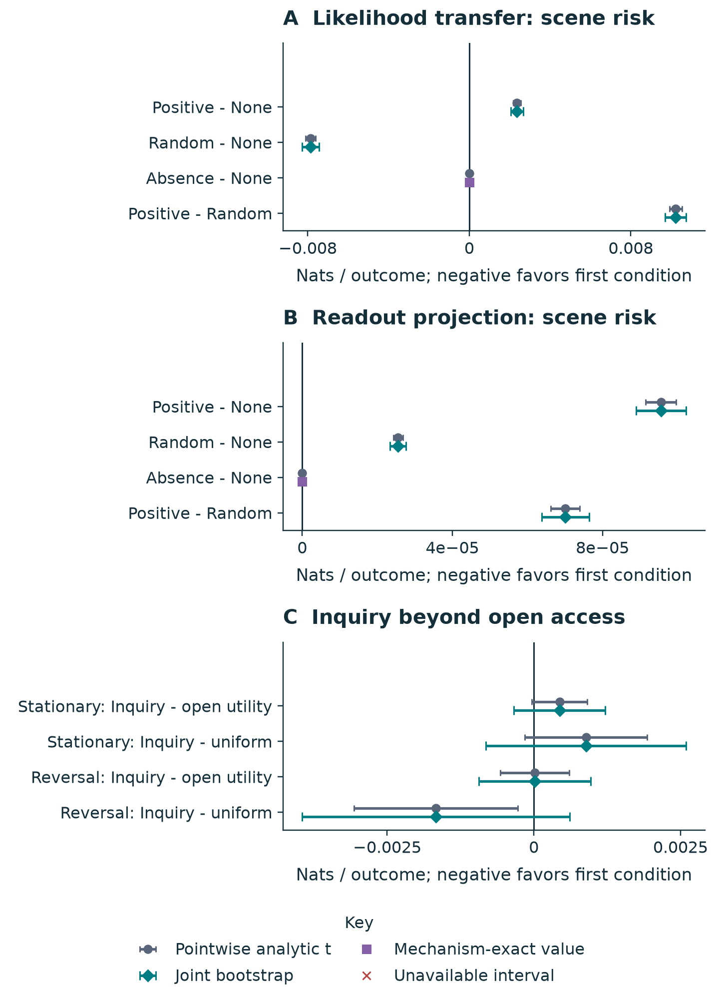

Pointwise analytic and joint bootstrap intervals; squares retain exact valuation identities.


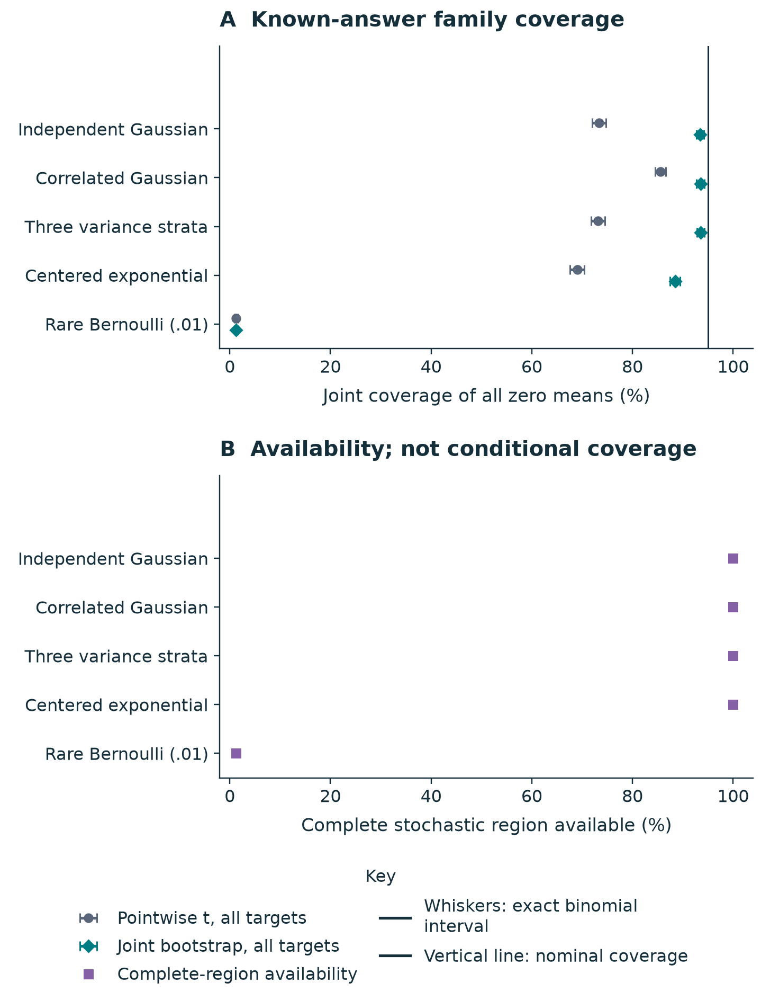

Independent experiment rates with exact binomial bounds retain skew and rare-event failures.


In [12]:
from thanks_for_nothing.joint_figures import joint_gaze_summary, joint_coverage
write_record(destination / 'data/gaze_uncertainty.json', joint)
for draw in (
    joint_gaze_summary(gaze, joint, destination / 'figures'),
    joint_coverage(joint, destination / 'figures'),
):
    display(Image(filename=str(destination / 'figures' / (draw.name + '.png')), alt=draw.alt))
    print(draw.alt)


## 8. A sample constant is not an exact population identity

An all-zero observed vector alone cannot justify a zero-width stochastic interval.
The mathematical example below deliberately lacks a mechanism-exact license.
It stays unavailable; changing that label to obtain a pleasing interval would
change the scientific claim. Coverage checks count unavailable families as
noncoverage, and retain the centered-exponential and rare-event failures.


In [13]:
from thanks_for_nothing.joint_contracts import JointBlock
from thanks_for_nothing.simultaneous import joint_region
accidental = JointBlock(
    'illustrative sample only', ('unknown_population_mean',),
    np.zeros((1, 4, 1), dtype=np.float64), (False,))
unknown = joint_region((accidental,), gaze.design.joint)
assert unknown.status == 'unavailable'
assert unknown.intervals[0].low is None
pprint(asdict(unknown))
workspace.cleanup()


{'blocks': (('illustrative sample only', 1, 4),),
 'confidence': 0.95,
 'critical_mc_high': None,
 'critical_mc_low': None,
 'critical_value': None,
 'draws': 0,
 'intervals': ({'high': None,
                'key': 'unknown_population_mean',
                'low': None,
                'mean': 0.0,
                'standard_error': 0.0,
                'status': 'unavailable_constant'},),
 'monte_carlo_confidence': 0.99,
 'status': 'unavailable'}


## Takeaways and disciplined extensions

We reproduce source before occupancy, add an explicit parameter-transfer
mechanism, and model revisable structural access. More positive-looking
probability is not sufficient evidence of better prediction. A correct
restriction can remain useful. Neither an open prior nor information-seeking
software measures the realization of emptiness.

Primary background: Yarbus (1967), complex-objects chapter; Castelhano,
Mack and Henderson (2009), DOI 10.1167/9.3.6; Mirza et al. (2019), DOI
10.1038/s41598-019-50138-8. See the dossier for actual reading scope.
Artwork: Munch, *The Scream* (1893), NG.M.00939; Nasjonalmuseet / Børre
Høstland photo CC BY 4.0. Display is rescaled with model overlays.

Further hypotheses need new declared designs: empirical eye tracking,
participant-level parameter recovery, pixel-based scene models and learning
across context changes are not implemented by this notebook.